# yolo12n training notebook (selected patients only)

This notebook trains/testing yolo12 nano using only these patients: `p4, p5, p7, p12, p15, p16, p17`.

Pipeline:
1. Collect image-label pairs from selected patient folders
2. Apply the same augmentations used in the reference scripts
3. Split into train/val/test
4. Train + validate + test yolo12n

In [1]:
# Install required packages for this notebook
%pip install ultralytics kornia albumentations opencv-python pandas matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


## Required folder structure
Expected under `pipeline_medsam2_3d`:
- `p4_extracted_pngs`, `p5_extracted_pngs`, `p7_extracted_pngs`, `p12_extracted_pngs`, `p15_extracted_pngs`, `p16_extracted_pngs`, `p17_extracted_pngs`
- `p4_labels`, `p5_labels`, `p7_labels`, `p12_labels`, `p15_labels`, `p16_labels`, `p17_labels`
- each patient folder has `axial/`, `coronal/`, `sagittal/`
- model weights file: `models/yolo12n/yolo12n.pt`

In [2]:
import sys
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
from tqdm import tqdm
from ultralytics import YOLO

# Force inline plotting in notebooks (VS Code/Colab)
%matplotlib inline
import matplotlib
matplotlib.rcParams['figure.dpi'] = 110

print('Python executable:', sys.executable)
print('Matplotlib backend:', matplotlib.get_backend())

Python executable: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2/.venv311/bin/python
Matplotlib backend: inline


## Optional (Colab): mount Google Drive
Use this if running in Colab and your dataset/project lives in Drive.

In [3]:
# Colab-safe drive mount
PROJECT_ROOT_OVERRIDE = None

try:
    import google.colab  # type: ignore
    from google.colab import drive  # type: ignore

    drive.mount('/content/drive')

    # Update this path to your Drive location of knee_ct_scan_segmentation
    PROJECT_ROOT_OVERRIDE = Path('/content/drive/MyDrive/knee_ct_scan_segmentation')
    print('Colab detected. PROJECT_ROOT_OVERRIDE =', PROJECT_ROOT_OVERRIDE)
except Exception:
    print('Not running in Colab. Using local paths.')

Not running in Colab. Using local paths.


## Optional (Colab): extract training_data.zip from Drive
Use this if your training folders are packed as `training_data.zip` in Drive.

In [ ]:
import zipfile

# Zip is expected inside pipeline_medsam2_3d in Drive/local project root
BASE_ROOT = PROJECT_ROOT_OVERRIDE if PROJECT_ROOT_OVERRIDE is not None else Path('/home/akshaj/Documents/projects/knee_ct_scan_segmentation')
ZIP_PATH = BASE_ROOT / 'pipeline_medsam2_3d' / 'training_data.zip'

# Since zip contains only patient folders, extract directly into pipeline_medsam2_3d
TARGET_ROOT = BASE_ROOT / 'pipeline_medsam2_3d'

if ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(TARGET_ROOT)
    print('Extracted zip:', ZIP_PATH)
    print('Extracted into:', TARGET_ROOT)
else:
    print('Zip not found:', ZIP_PATH)
    print('Expected location: <project_root>/pipeline_medsam2_3d/training_data.zip')

## Config
Set paths, selected patients, and training hyperparameters.

In [4]:
# Base project paths
DEFAULT_LOCAL_PROJECT_ROOT = Path('/home/akshaj/Documents/projects/knee_ct_scan_segmentation')
PROJECT_ROOT = PROJECT_ROOT_OVERRIDE if PROJECT_ROOT_OVERRIDE is not None else DEFAULT_LOCAL_PROJECT_ROOT
PIPELINE_DIR = PROJECT_ROOT / 'pipeline_medsam2_3d'

# Only these patients are used
SELECTED_PATIENTS = ['p4', 'p5', 'p7', 'p12', 'p15', 'p16', 'p17']
ALL_VIEWS = ['axial', 'coronal', 'sagittal']

# 4 models: per-view + all views
MODEL_SPECS = {
    # 'axial': ['axial'],
    'coronal': ['coronal'],
    # 'sagittal': ['sagittal'],
    # 'all_views': ['axial', 'coronal', 'sagittal'],
}

# Weights must be inside pipeline_medsam2_3d
WEIGHTS_DIR = PIPELINE_DIR / 'models' / 'yolo12n'
WEIGHTS = WEIGHTS_DIR / 'yolo12n.pt'

# Output roots
DATA_ROOT = PIPELINE_DIR / 'yolo12_selected_patients_dataset'
RUNS_ROOT = PIPELINE_DIR / 'runs_yolo12'

TRAIN_RATIO = 0.85
VAL_RATIO = 0.075
TEST_RATIO = 0.075
SEED = 42

# Same augmentations as reference yolo_aug.py
N_SSR = 3
SHIFT_LIMIT = 0.1
SCALE_LIMIT = 0.15
ROTATE_LIMIT = 30
MIN_VIS = 0.30
MIN_WH = 0.01

# Reuse existing augmented files if present
# True: skip rebuilding aug folders when they already contain files
# False: clear and regenerate augmentations each run
REUSE_AUGMENTATIONS = True

# Reuse split files if already present (train/val/test)
REUSE_SPLITS = True

# Training config
IMGSZ = 512
EPOCHS = 10
BATCH = 32
WORKERS = 4

random.seed(SEED)
np.random.seed(SEED)

WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_ROOT.mkdir(parents=True, exist_ok=True)
RUNS_ROOT.mkdir(parents=True, exist_ok=True)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('PIPELINE_DIR:', PIPELINE_DIR)
print('WEIGHTS path:', WEIGHTS)
print('DATA_ROOT:', DATA_ROOT)
print('RUNS_ROOT:', RUNS_ROOT)
print('Patients:', SELECTED_PATIENTS)
print('Model specs:', MODEL_SPECS)
print('REUSE_AUGMENTATIONS:', REUSE_AUGMENTATIONS)
print('REUSE_SPLITS:', REUSE_SPLITS)

PROJECT_ROOT: /home/akshaj/Documents/projects/knee_ct_scan_segmentation
PIPELINE_DIR: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d
WEIGHTS path: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/models/yolo12n/yolo12n.pt
DATA_ROOT: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/yolo12_selected_patients_dataset
RUNS_ROOT: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/runs_yolo12
Patients: ['p4', 'p5', 'p7', 'p12', 'p15', 'p16', 'p17']
Model specs: {'coronal': ['coronal']}
REUSE_AUGMENTATIONS: True
REUSE_SPLITS: True


## Auto-download YOLO12n weights
If `models/yolo12n/yolo12n.pt` is missing, this cell fetches it into the same local/Drive folder used by this notebook.

In [5]:
def ensure_yolo12n_weights(weights_path: Path):
    """Use Ultralytics-native weight resolution/download and store in target path."""
    weights_path.parent.mkdir(parents=True, exist_ok=True)

    if weights_path.exists() and weights_path.stat().st_size > 0:
        print('Weights found:', weights_path)
        return weights_path

    print('Weights missing. Resolving with Ultralytics...')

    # Ultralytics built-in model resolution/download
    tmp_model = YOLO('yolo12n.pt')

    candidates = [Path('yolo12n.pt')]

    for obj in [tmp_model, getattr(tmp_model, 'model', None)]:
        if obj is None:
            continue
        for attr in ['ckpt_path', 'pt_path']:
            v = getattr(obj, attr, None)
            if v:
                candidates.append(Path(v))

    resolved = None
    for p in candidates:
        if p.exists() and p.is_file() and p.stat().st_size > 0:
            resolved = p
            break

    if resolved is None:
        raise FileNotFoundError('Ultralytics could not resolve yolo12n.pt')

    if resolved.resolve() != weights_path.resolve():
        shutil.copy2(resolved, weights_path)

    print('Weights ready at:', weights_path)
    return weights_path


WEIGHTS = ensure_yolo12n_weights(WEIGHTS)
print('Using weights:', WEIGHTS)

Weights found: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/models/yolo12n/yolo12n.pt
Using weights: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/models/yolo12n/yolo12n.pt


## 1) Collect data from selected patients
Copies only image-label pairs from the selected patient PNG/label folders.

In [6]:
def reset_dir(path: Path):
    path.mkdir(parents=True, exist_ok=True)
    for f in path.glob('*'):
        if f.is_file():
            f.unlink()


def collect_pairs_for_views(target_views, raw_im_dir: Path, raw_lb_dir: Path):
    """Copy matched image-label pairs for selected patients and views."""
    reset_dir(raw_im_dir)
    reset_dir(raw_lb_dir)

    copied = 0
    skipped = 0

    for p in SELECTED_PATIENTS:
        img_root = PIPELINE_DIR / f'{p}_extracted_pngs'
        lb_root = PIPELINE_DIR / f'{p}_labels'

        if not img_root.exists() or not lb_root.exists():
            print(f'[WARN] Missing folder for {p}')
            continue

        for view in target_views:
            view_im = img_root / view
            view_lb = lb_root / view
            if not view_im.exists() or not view_lb.exists():
                print(f'[WARN] Missing view folder: {p}/{view}')
                continue

            image_files = sorted(
                [x for x in view_im.glob('*.png')]
                + [x for x in view_im.glob('*.jpg')]
                + [x for x in view_im.glob('*.jpeg')]
            )

            for im_path in image_files:
                stem = im_path.stem
                lb_path = view_lb / f'{stem}.txt'
                if not lb_path.exists():
                    skipped += 1
                    continue

                out_base = f'{p}_{view}_{stem}'
                shutil.copy2(im_path, raw_im_dir / f'{out_base}{im_path.suffix.lower()}')
                shutil.copy2(lb_path, raw_lb_dir / f'{out_base}.txt')
                copied += 1

    return copied, skipped

## 2) Kornia augmentation + dataset build helpers
Uses Kornia for affine augmentations (GPU if available), then writes split datasets.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
import kornia as K


def read_yolo_labels(txt_path: Path):
    boxes, classes = [], []
    if not txt_path.exists():
        return boxes, classes
    with open(txt_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            if len(parts) != 5:
                continue
            cls, x, y, w, h = parts
            classes.append(int(cls))
            boxes.append([float(x), float(y), float(w), float(h)])
    return boxes, classes


def write_yolo_labels(txt_path: Path, boxes, classes):
    with open(txt_path, 'w') as f:
        for (b, c) in zip(boxes, classes):
            x, y, w, h = b
            x = min(max(x, 0.0), 1.0)
            y = min(max(y, 0.0), 1.0)
            w = min(max(w, 0.0), 1.0)
            h = min(max(h, 0.0), 1.0)
            if w < MIN_WH or h < MIN_WH:
                continue
            f.write(f'{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n')


def image_to_tensor_rgb01(image_bgr: np.ndarray, device: torch.device) -> torch.Tensor:
    rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    t = torch.from_numpy(rgb).to(device=device, dtype=torch.float32) / 255.0
    return t.permute(2, 0, 1).unsqueeze(0)


def tensor_to_image_bgr(image_t: torch.Tensor) -> np.ndarray:
    img = image_t.detach().cpu().squeeze(0).permute(1, 2, 0).clamp(0, 1).numpy()
    img = (img * 255.0).astype(np.uint8)
    return cv2.cvtColor(img, cv2.COLOR_RGB2BGR)


def yolo_to_xyxy_px(bboxes, w: int, h: int) -> np.ndarray:
    if len(bboxes) == 0:
        return np.zeros((0, 4), dtype=np.float32)
    arr = np.array(bboxes, dtype=np.float32)
    xc, yc, bw, bh = arr[:, 0], arr[:, 1], arr[:, 2], arr[:, 3]
    x1 = (xc - bw / 2.0) * w
    y1 = (yc - bh / 2.0) * h
    x2 = (xc + bw / 2.0) * w
    y2 = (yc + bh / 2.0) * h
    return np.stack([x1, y1, x2, y2], axis=1)


def xyxy_px_to_yolo(xyxy: np.ndarray, w: int, h: int):
    if len(xyxy) == 0:
        return []
    x1, y1, x2, y2 = xyxy[:, 0], xyxy[:, 1], xyxy[:, 2], xyxy[:, 3]
    bw = (x2 - x1) / w
    bh = (y2 - y1) / h
    xc = ((x1 + x2) / 2.0) / w
    yc = ((y1 + y2) / 2.0) / h
    return np.stack([xc, yc, bw, bh], axis=1).tolist()


def transform_boxes_affine(bboxes, classes, w: int, h: int, m: torch.Tensor):
    if len(bboxes) == 0:
        return [], []

    xyxy = yolo_to_xyxy_px(bboxes, w, h)
    orig_area = np.maximum(0.0, (xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1]))

    corners = np.stack([
        np.stack([xyxy[:, 0], xyxy[:, 1]], axis=1),
        np.stack([xyxy[:, 2], xyxy[:, 1]], axis=1),
        np.stack([xyxy[:, 2], xyxy[:, 3]], axis=1),
        np.stack([xyxy[:, 0], xyxy[:, 3]], axis=1),
    ], axis=1)

    ones = np.ones((corners.shape[0], corners.shape[1], 1), dtype=np.float32)
    corners_h = np.concatenate([corners, ones], axis=2)

    m_np = m.detach().cpu().numpy().astype(np.float32)
    warped = corners_h @ m_np.T

    x_min = warped[:, :, 0].min(axis=1)
    y_min = warped[:, :, 1].min(axis=1)
    x_max = warped[:, :, 0].max(axis=1)
    y_max = warped[:, :, 1].max(axis=1)

    x_min = np.clip(x_min, 0, w)
    y_min = np.clip(y_min, 0, h)
    x_max = np.clip(x_max, 0, w)
    y_max = np.clip(y_max, 0, h)

    new_xyxy = np.stack([x_min, y_min, x_max, y_max], axis=1)
    new_area = np.maximum(0.0, (x_max - x_min) * (y_max - y_min))
    visibility = np.where(orig_area > 1e-6, new_area / np.maximum(orig_area, 1e-6), 0.0)

    keep = visibility >= MIN_VIS
    keep &= (x_max - x_min) >= (MIN_WH * w)
    keep &= (y_max - y_min) >= (MIN_WH * h)

    kept_xyxy = new_xyxy[keep]
    kept_cls = np.array(classes)[keep].tolist()
    kept_yolo = xyxy_px_to_yolo(kept_xyxy, w, h)
    return kept_yolo, kept_cls


def kornia_random_affine(image_t: torch.Tensor, bboxes, classes):
    _, _, h, w = image_t.shape

    angle = float(np.random.uniform(-ROTATE_LIMIT, ROTATE_LIMIT))
    scale = float(np.random.uniform(1.0 - SCALE_LIMIT, 1.0 + SCALE_LIMIT))
    tx = float(np.random.uniform(-SHIFT_LIMIT, SHIFT_LIMIT) * w)
    ty = float(np.random.uniform(-SHIFT_LIMIT, SHIFT_LIMIT) * h)

    theta = np.deg2rad(angle)
    c, s = np.cos(theta), np.sin(theta)
    cx, cy = w / 2.0, h / 2.0

    m = torch.tensor([
        [scale * c, scale * s, (1 - scale * c) * cx - scale * s * cy + tx],
        [-scale * s, scale * c, scale * s * cx + (1 - scale * c) * cy + ty],
    ], dtype=torch.float32, device=image_t.device)

    warped = K.geometry.transform.warp_affine(
        image_t,
        m.unsqueeze(0),
        dsize=(h, w),
        mode='bilinear',
        padding_mode='zeros',
        align_corners=True,
    )

    out_boxes, out_cls = transform_boxes_affine(bboxes, classes, w=w, h=h, m=m)
    return warped, out_boxes, out_cls


def hflip_boxes(bboxes):
    return [[1.0 - x, y, w, h] for x, y, w, h in bboxes]


def vflip_boxes(bboxes):
    return [[x, 1.0 - y, w, h] for x, y, w, h in bboxes]


def augment_dataset(raw_im_dir: Path, raw_lb_dir: Path, aug_im_dir: Path, aug_lb_dir: Path, device: torch.device):
    images = sorted([x for x in raw_im_dir.glob('*') if x.suffix.lower() in ['.png', '.jpg', '.jpeg']])
    assert images, f'No raw images in {raw_im_dir}'

    if REUSE_AUGMENTATIONS:
        aug_existing = sorted([x for x in aug_im_dir.glob('*') if x.suffix.lower() in ['.png', '.jpg', '.jpeg']]) if aug_im_dir.exists() else []
        if len(aug_existing) > 0:
            print(f'Reusing augmentations from {aug_im_dir} ({len(aug_existing)} images)')
            return len(images), len(aug_existing)

    reset_dir(aug_im_dir)
    reset_dir(aug_lb_dir)

    total_written = 0
    for im_path in tqdm(images, desc=f'Augmenting {raw_im_dir.parent.name}'):
        base = im_path.stem
        ext = im_path.suffix.lower()
        lb_path = raw_lb_dir / f'{base}.txt'

        img_bgr = cv2.imread(str(im_path), cv2.IMREAD_COLOR)
        if img_bgr is None:
            continue

        bboxes, classes = read_yolo_labels(lb_path)
        img_t = image_to_tensor_rgb01(img_bgr, device)

        cv2.imwrite(str(aug_im_dir / f'{base}{ext}'), img_bgr)
        write_yolo_labels(aug_lb_dir / f'{base}.txt', bboxes, classes)
        total_written += 1

        for i in range(N_SSR):
            aug_t, aug_boxes, aug_cls = kornia_random_affine(img_t, bboxes, classes)
            aug_img_bgr = tensor_to_image_bgr(aug_t)
            cv2.imwrite(str(aug_im_dir / f'{base}_ssr{i+1}.jpg'), aug_img_bgr)
            write_yolo_labels(aug_lb_dir / f'{base}_ssr{i+1}.txt', aug_boxes, aug_cls)
            total_written += 1

        hflip_t = torch.flip(img_t, dims=[3])
        cv2.imwrite(str(aug_im_dir / f'{base}_hflip.jpg'), tensor_to_image_bgr(hflip_t))
        write_yolo_labels(aug_lb_dir / f'{base}_hflip.txt', hflip_boxes(bboxes), classes)
        total_written += 1

        vflip_t = torch.flip(img_t, dims=[2])
        cv2.imwrite(str(aug_im_dir / f'{base}_vflip.jpg'), tensor_to_image_bgr(vflip_t))
        write_yolo_labels(aug_lb_dir / f'{base}_vflip.txt', vflip_boxes(bboxes), classes)
        total_written += 1

    return len(images), total_written


def split_dataset(aug_im_dir: Path, aug_lb_dir: Path, dataset_root: Path):
    train_im = dataset_root / 'train' / 'images'
    val_im = dataset_root / 'val' / 'images'
    test_im = dataset_root / 'test' / 'images'

    # Reuse existing split to avoid expensive recopy (very useful on Colab + Drive)
    if REUSE_SPLITS:
        existing = {
            'train': len(list(train_im.glob('*'))) if train_im.exists() else 0,
            'val': len(list(val_im.glob('*'))) if val_im.exists() else 0,
            'test': len(list(test_im.glob('*'))) if test_im.exists() else 0,
        }
        if sum(existing.values()) > 0:
            print(f"Reusing split folders in {dataset_root} -> {existing}")
            return existing

    for split in ['train', 'val', 'test']:
        reset_dir(dataset_root / split / 'images')
        reset_dir(dataset_root / split / 'labels')

    images = sorted([x for x in aug_im_dir.glob('*') if x.suffix.lower() in ['.png', '.jpg', '.jpeg']])
    assert images, f'No augmented images in {aug_im_dir}'

    random.shuffle(images)
    n_total = len(images)
    n_train = int(n_total * TRAIN_RATIO)
    n_val = int(n_total * VAL_RATIO)

    split_map = {
        'train': images[:n_train],
        'val': images[n_train:n_train + n_val],
        'test': images[n_train + n_val:],
    }

    for split, files in split_map.items():
        for im_path in tqdm(files, desc=f'Copying {dataset_root.name}/{split}'):
            stem = im_path.stem
            lb_path = aug_lb_dir / f'{stem}.txt'
            out_im = dataset_root / split / 'images' / im_path.name
            out_lb = dataset_root / split / 'labels' / f'{stem}.txt'

            shutil.copyfile(im_path, out_im)
            if lb_path.exists():
                shutil.copyfile(lb_path, out_lb)
            else:
                out_lb.write_text('')

    return {k: len(v) for k, v in split_map.items()}


def write_yaml(dataset_root: Path):
    yaml_path = dataset_root / 'data.yaml'
    yaml_text = f'''# Auto-generated for yolo12\npath: .\ntrain: {(dataset_root / 'train' / 'images').as_posix()}\nval: {(dataset_root / 'val' / 'images').as_posix()}\ntest: {(dataset_root / 'test' / 'images').as_posix()}\n\nnames:\n  0: class_0\n'''
    yaml_path.write_text(yaml_text)
    return yaml_path


def prepare_datasets_all_models():
    aug_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Kornia augmentation device:', aug_device)

    dataset_info = {}
    for model_name, model_views in MODEL_SPECS.items():
        print('\n' + '=' * 80)
        print(f'Prepare data: {model_name} | views={model_views}')

        model_root = DATA_ROOT / model_name
        raw_im_dir = model_root / 'raw' / 'images'
        raw_lb_dir = model_root / 'raw' / 'labels'
        aug_im_dir = model_root / 'aug' / 'images'
        aug_lb_dir = model_root / 'aug' / 'labels'

        copied, skipped = collect_pairs_for_views(model_views, raw_im_dir, raw_lb_dir)
        print(f'Collected pairs: {copied}, skipped without label: {skipped}')

        n_raw, n_aug = augment_dataset(raw_im_dir, raw_lb_dir, aug_im_dir, aug_lb_dir, device=aug_device)
        print(f'Raw images: {n_raw}, after augmentation: {n_aug}')

        split_sizes = split_dataset(aug_im_dir, aug_lb_dir, model_root)
        print('Split sizes:', split_sizes)

        yaml_path = write_yaml(model_root)
        dataset_info[model_name] = {
            'views': model_views,
            'model_root': model_root,
            'yaml_path': yaml_path,
            'split_sizes': split_sizes,
        }

    return dataset_info


def train_and_evaluate_all_models(dataset_info):
    assert WEIGHTS.exists(), f'Weights not found: {WEIGHTS}'
    assert WEIGHTS.name.lower().startswith('yolo12'), f'Unexpected weights file: {WEIGHTS}'

    train_device = 0 if torch.cuda.is_available() else 'cpu'
    print('Training device:', train_device)
    print('Using weights:', WEIGHTS)

    run_summaries = []
    curve_frames = {}

    for model_name, info in dataset_info.items():
        model_views = info['views']
        yaml_path = info['yaml_path']

        print('\n' + '=' * 80)
        print(f'Train model: {model_name} | views={model_views}')

        run_dir = RUNS_ROOT / f'exp_{model_name}'
        best = run_dir / 'weights' / 'best.pt'

        if not best.exists():
            model = YOLO(str(WEIGHTS))
            results = model.train(
                data=str(yaml_path),
                imgsz=IMGSZ,
                epochs=EPOCHS,
                batch=BATCH,
                workers=WORKERS,
                project=str(RUNS_ROOT),
                name=f'exp_{model_name}',
                pretrained=True,
                patience=20,
                device=train_device,
            )

            save_dir = getattr(results, 'save_dir', None)
            if save_dir is None:
                raise RuntimeError(f'Could not resolve save_dir for {model_name}')
            run_dir = Path(save_dir)
            best = run_dir / 'weights' / 'best.pt'
        else:
            print(f'Reusing existing checkpoint: {best}')
        best = run_dir / 'weights' / 'best.pt'
        assert best.exists(), f'best.pt missing for {model_name}'

        best_model = YOLO(str(best))
        _ = best_model.val(data=str(yaml_path), split='val', imgsz=IMGSZ, device=train_device)
        test_metrics = best_model.val(data=str(yaml_path), split='test', imgsz=IMGSZ, device=train_device)

        # Ultralytics DetMetrics does not expose box_loss/cls_loss/dfl_loss on val/test results.
        test_results = getattr(test_metrics, 'results_dict', {}) or {}
        test_map50 = test_results.get('metrics/mAP50(B)', np.nan)
        test_map5095 = test_results.get('metrics/mAP50-95(B)', np.nan)

        if pd.isna(test_map50):
            test_map50 = getattr(getattr(test_metrics, 'box', None), 'map50', np.nan)
        if pd.isna(test_map5095):
            test_map5095 = getattr(getattr(test_metrics, 'box', None), 'map', np.nan)

        test_map50 = float(test_map50) if not pd.isna(test_map50) else np.nan
        test_map5095 = float(test_map5095) if not pd.isna(test_map5095) else np.nan

        # Keep a comparable scalar in the summary table.
        test_loss = float(1.0 - test_map5095) if not pd.isna(test_map5095) else np.nan

        results_csv = run_dir / 'results.csv'
        assert results_csv.exists(), f'results.csv missing for {model_name}'
        df = pd.read_csv(results_csv)
        curve_frames[model_name] = df

        run_summaries.append({
            'model': model_name,
            'views': ','.join(model_views),
            'run_dir': str(run_dir),
            'train_loss_final': float(df['train/box_loss'].iloc[-1] + df['train/cls_loss'].iloc[-1] + df['train/dfl_loss'].iloc[-1]),
            'val_loss_final': float(df['val/box_loss'].iloc[-1] + df['val/cls_loss'].iloc[-1] + df['val/dfl_loss'].iloc[-1]),
            'test_loss': test_loss,
            'test_map50': test_map50,
            'test_map50_95': test_map5095,
        })

    summary_df = pd.DataFrame(run_summaries)
    return summary_df, curve_frames

## 2.1) Build datasets (collect + Kornia augmentation + split)

In [8]:
dataset_info = prepare_datasets_all_models()
pd.DataFrame([
    {
        'model': k,
        'views': ','.join(v['views']),
        'train': v['split_sizes']['train'],
        'val': v['split_sizes']['val'],
        'test': v['split_sizes']['test'],
    }
    for k, v in dataset_info.items()
]).sort_values('model').reset_index(drop=True)

Kornia augmentation device: cuda

Prepare data: coronal | views=['coronal']
Collected pairs: 845, skipped without label: 2739
Reusing augmentations from /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/yolo12_selected_patients_dataset/coronal/aug/images (5070 images)
Raw images: 845, after augmentation: 5070
Reusing split folders in /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/yolo12_selected_patients_dataset/coronal -> {'train': 4309, 'val': 380, 'test': 381}
Split sizes: {'train': 4309, 'val': 380, 'test': 381}


,model,views,train,val,test
0,coronal,coronal,4309,380,381


## 2.2) Train and evaluate all 4 models

In [9]:
summary_df, curve_frames = train_and_evaluate_all_models(dataset_info)
summary_df

Training device: 0
Using weights: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/models/yolo12n/yolo12n.pt

Train model: coronal | views=['coronal']
Reusing existing checkpoint: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/runs_yolo12/exp_coronal/weights/best.pt
Ultralytics 8.4.14 🚀 Python-3.11.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7808MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 1.5±1.5 ms, read: 64.1±58.7 MB/s, size: 45.4 KB)
val: Scanning /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/yolo12_selected_patients_dataset/coronal/val/labels.cache... 380 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 380/380 59.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 6.7it/s 3.6s<0.1s
                   all        380    

,model,views,run_dir,train_loss_final,val_loss_final,test_loss,test_map50,test_map50_95
0,coronal,coronal,/home/akshaj/Documents/projects/knee_ct_scan_s...,2.53869,2.41203,0.408582,0.808035,0.591418


## 3) Training summary for all 4 models

In [34]:
summary_df = summary_df.sort_values('model').reset_index(drop=True)
summary_df

,model,views,run_dir,train_loss_final,val_loss_final,test_loss,test_map50,test_map50_95
0,all_views,"axial,coronal,sagittal",/home/akshaj/Documents/projects/knee_ct_scan_s...,2.00933,1.90992,0.234697,0.917985,0.765303
1,axial,axial,/home/akshaj/Documents/projects/knee_ct_scan_s...,1.75450,1.63338,0.145242,0.960655,0.854758
2,coronal,coronal,/home/akshaj/Documents/projects/knee_ct_scan_s...,2.53869,2.41203,0.408582,0.808035,0.591418
3,sagittal,sagittal,/home/akshaj/Documents/projects/knee_ct_scan_s...,2.27777,2.19637,0.288077,0.913815,0.711923


## 4) Compare losses across axial/coronal/sagittal/all_views

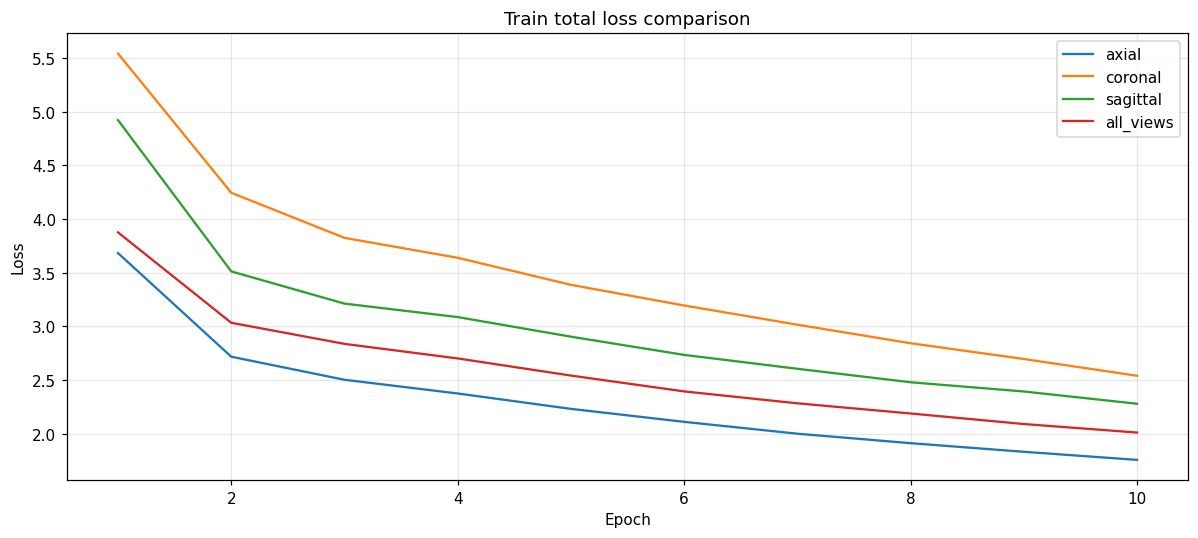

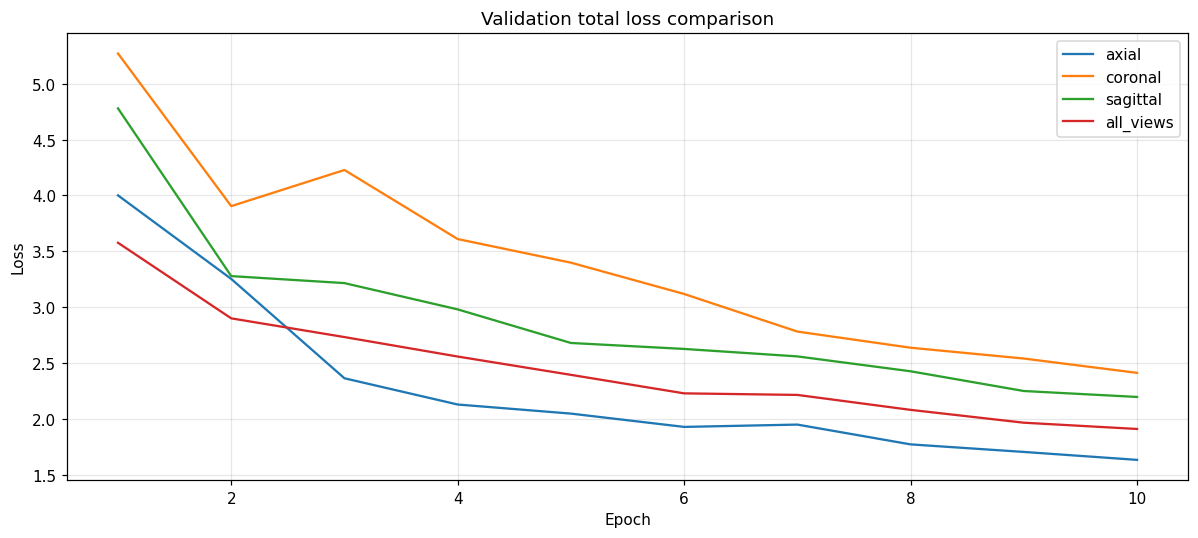

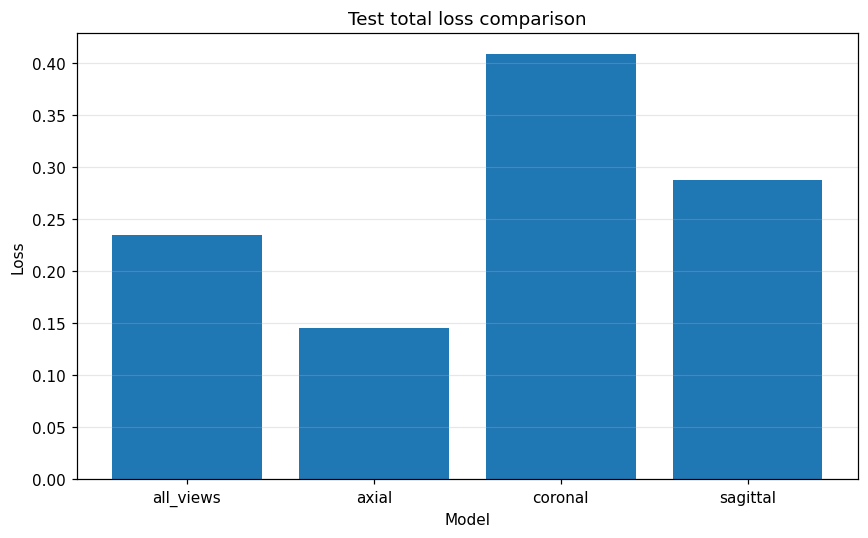

In [35]:
# Compare train/val curves across all models
train_cols = ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']
val_cols = ['val/box_loss', 'val/cls_loss', 'val/dfl_loss']

plt.figure(figsize=(11, 5))
for model_name, df in curve_frames.items():
    train_total = df[train_cols].sum(axis=1)
    x = df['epoch'] if 'epoch' in df.columns else range(len(df))
    plt.plot(x, train_total, label=f'{model_name}')
plt.title('Train total loss comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
for model_name, df in curve_frames.items():
    val_total = df[val_cols].sum(axis=1)
    x = df['epoch'] if 'epoch' in df.columns else range(len(df))
    plt.plot(x, val_total, label=f'{model_name}')
plt.title('Validation total loss comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Test loss is measured once per model after training, so compare as bars
plt.figure(figsize=(8, 5))
plt.bar(summary_df['model'], summary_df['test_loss'])
plt.title('Test total loss comparison')
plt.xlabel('Model')
plt.ylabel('Loss')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 5) Optional: run-level notes

In [36]:
print('Run folders:')
for row in summary_df.itertuples(index=False):
    print(f"- {row.model}: {row.run_dir}")

Run folders:
- all_views: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/runs_yolo12/exp_all_views
- axial: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/runs_yolo12/exp_axial
- coronal: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/runs_yolo12/exp_coronal
- sagittal: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/runs_yolo12/exp_sagittal


## Optional detailed per-model curves

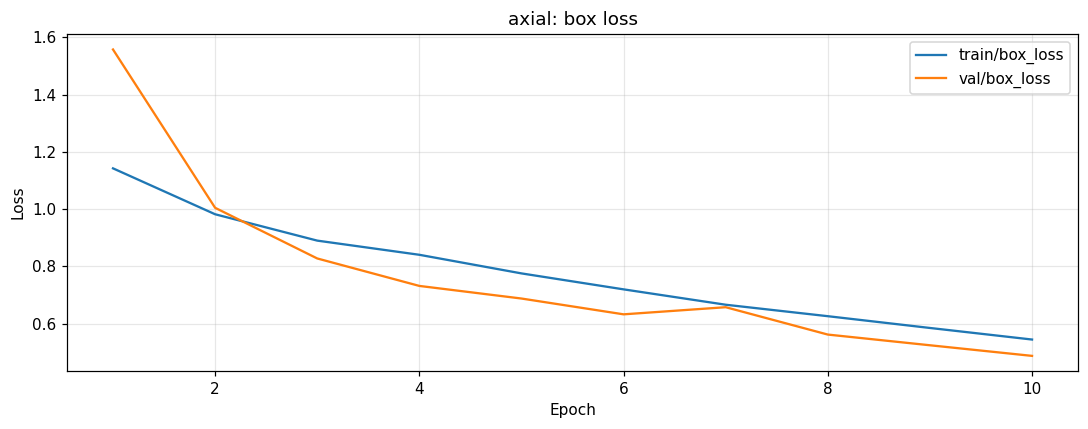

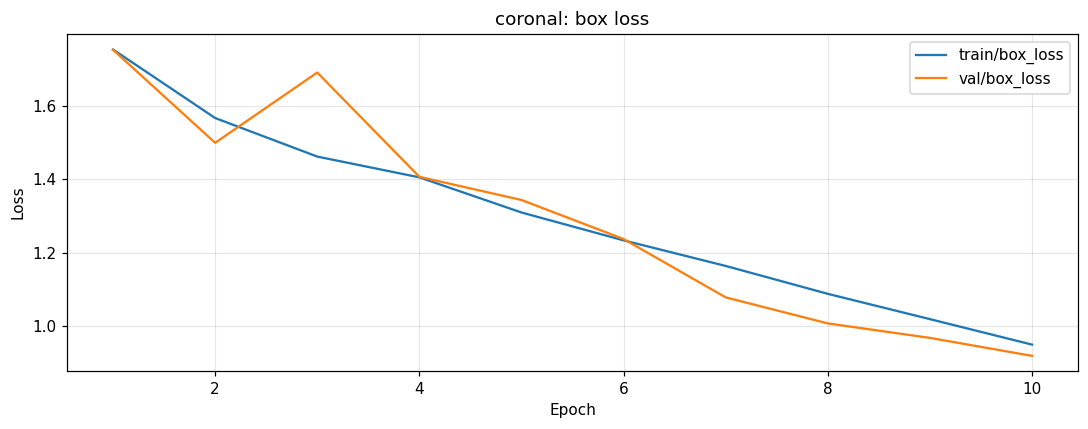

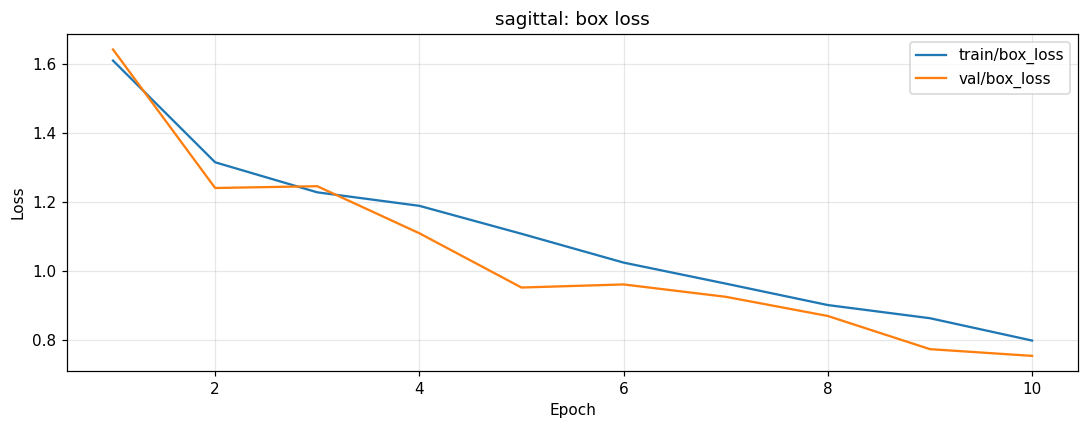

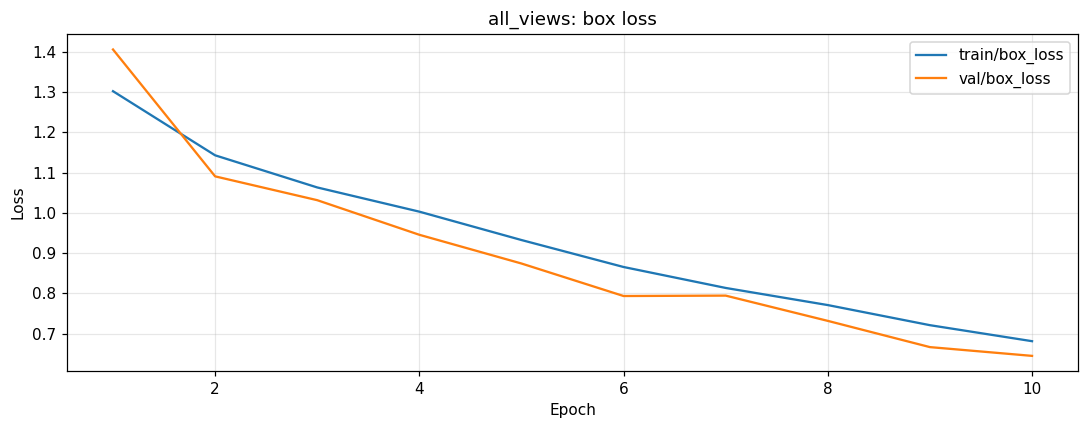

In [37]:
# Optional detailed curves per model
for model_name, df in curve_frames.items():
    plt.figure(figsize=(10, 4))
    x = df['epoch'] if 'epoch' in df.columns else range(len(df))
    plt.plot(x, df['train/box_loss'], label='train/box_loss')
    plt.plot(x, df['val/box_loss'], label='val/box_loss')
    plt.title(f'{model_name}: box loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 6) Export summary table

In [38]:
# Save summary CSV for quick comparison
summary_csv = RUNS_ROOT / 'selected_patients_4model_loss_summary.csv'
summary_df.to_csv(summary_csv, index=False)
print('Saved:', summary_csv)
summary_df

Saved: /home/akshaj/Documents/projects/knee_ct_scan_segmentation/pipeline_medsam2_3d/runs_yolo12/selected_patients_4model_loss_summary.csv


,model,views,run_dir,train_loss_final,val_loss_final,test_loss,test_map50,test_map50_95
0,all_views,"axial,coronal,sagittal",/home/akshaj/Documents/projects/knee_ct_scan_s...,2.00933,1.90992,0.234697,0.917985,0.765303
1,axial,axial,/home/akshaj/Documents/projects/knee_ct_scan_s...,1.75450,1.63338,0.145242,0.960655,0.854758
2,coronal,coronal,/home/akshaj/Documents/projects/knee_ct_scan_s...,2.53869,2.41203,0.408582,0.808035,0.591418
3,sagittal,sagittal,/home/akshaj/Documents/projects/knee_ct_scan_s...,2.27777,2.19637,0.288077,0.913815,0.711923


## Notes
- Uses only `p4, p5, p7, p12, p15, p16, p17` data.
- Trains 4 models: `axial`, `coronal`, `sagittal`, `all_views`.
- Weights are loaded from `pipeline_medsam2_3d/models/yolo12n/yolo12n.pt`.
- Augmentations match reference (`yolo_aug.py`): 3x SSR + hflip + vflip.
- Split matches reference (`splitting.py`): 85/7.5/7.5.
- Comparison plots include train loss, val loss (curves), and test loss (bars).